# 4. ECL, Staging, Backtest and Monitoring
Combine PD, LGD and EAD into Ind AS 109 / IFRS 9 expected credit loss for the 2018 book. Then backtest the loss estimates on 2017 loans, check pricing by grade, and monitor model stability with PSI and CSI.

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

## Load models and data
The 2018 live book is merged with its PD scores from Notebook 2. The reporting date is the snapshot date of the data.

In [82]:
pd_art = joblib.load("../artifacts/pd_model.pkl")
lgd_art = joblib.load("../artifacts/lgd_ead_models.pkl")

live = pd.read_parquet("../data/live.parquet").merge(
    pd.read_parquet("../data/live_scored.parquet")[["id", "pd_12m", "score"]], on="id")
test = pd.read_parquet("../data/test.parquet").merge(
    pd.read_parquet("../data/test_scored.parquet")[["id", "pd_12m", "score"]], on="id")
train = pd.read_parquet("../data/train.parquet")
train_scored = pd.read_parquet("../data/train_scored.parquet")

snapshot = max(live["last_pymnt_d"].max(), test["last_pymnt_d"].max())
print("Reporting date:", snapshot)
print("Live:", live.shape, " Test:", test.shape)

Reporting date: 2019-03-01 00:00:00
Live: (495242, 38)  Test: (443579, 38)


## LGD helper
Same feature steps as Notebook 3, using the saved medians and columns. Dummy columns are reindexed to the training columns, so a category missing from the new data doesn't shift anything.

In [83]:
def make_X(df):
    X = df[lgd_art["num_cols"]].fillna(lgd_art["medians"])
    X["annual_inc"] = np.log1p(X["annual_inc"])
    X = pd.concat([X, pd.get_dummies(df[lgd_art["cat_cols"]].astype(str), dtype=float)], axis=1)
    return X.reindex(columns=lgd_art["X_cols"], fill_value=0)

def predict_lgd(df):
    X = make_X(df)
    p = lgd_art["lgd_step1"].predict_proba(X)[:, 1]
    rate = lgd_art["lgd_step2"].predict(X).clip(0, 1)
    return (1 - p * rate).clip(0, 1)

## Outstanding book
Keep 2018 loans still open at the reporting date. EAD today = outstanding principal. Remaining life = term − months on book.

In [84]:
open_status = ["Current", "In Grace Period", "Late (16-30 days)", "Late (31-120 days)", "Default"]
book = live[live["loan_status"].isin(open_status)].copy()

book["months_on_book"] = (snapshot.year - book["issue_d"].dt.year) * 12 + (snapshot.month - book["issue_d"].dt.month)
book["remaining"] = (book["term"] - book["months_on_book"]).clip(lower=1)
book["ead"] = book["out_prncp"]
book["lgd"] = predict_lgd(book)

print("Open loans:", len(book), "| Total EAD:", round(book["ead"].sum() / 1e6, 1), "mn")
print(book["loan_status"].value_counts())

Open loans: 438931 | Total EAD: 5946.5 mn
loan_status
Current               427181
Late (31-120 days)      7221
In Grace Period         2919
Late (16-30 days)       1603
Default                    7
Name: count, dtype: int64


## Staging
- **Stage 3 (credit-impaired):** 31+ days past due or in default
- **Stage 2 (significant increase in credit risk):** 1–30 days past due (the 30 DPD backstop), or FICO dropped 60+ points since origination *and* is now below 640
- **Stage 1:** everything else

The updated FICO is only used here for staging, not as a PD feature.

In [85]:
last_fico = book["last_fico_range_high"].where(book["last_fico_range_high"] >= 300)
fico_drop = book["fico_range_high"] - last_fico
sicr_fico = (fico_drop >= 60) & (last_fico < 640)

book["stage"] = 1
book.loc[book["loan_status"].isin(["In Grace Period", "Late (16-30 days)"]) | sicr_fico, "stage"] = 2
book.loc[book["loan_status"].isin(["Late (31-120 days)", "Default"]), "stage"] = 3

print(book["stage"].value_counts().sort_index())
print(book["stage"].value_counts(normalize=True).sort_index().round(3))

stage
1    415181
2     16522
3      7228
Name: count, dtype: int64
stage
1    0.946
2    0.038
3    0.016
Name: proportion, dtype: float64


## SICR threshold analysis
Updated FICO scores are noisy (std of change ≈ 40 pts). Testing relative and absolute thresholds to find a rule that captures real deterioration.

In [86]:
print("last FICO = 0:", (book["last_fico_range_high"] == 0).sum())
print("last FICO < 300:", (book["last_fico_range_high"] < 300).sum())

drop = book["fico_range_high"] - book["last_fico_range_high"]
print(drop[book["last_fico_range_high"] >= 300].describe().round(1))

last FICO = 0: 3
last FICO < 300: 3
count    438928.0
mean         -1.1
std          39.5
min        -170.0
25%         -25.0
50%          -5.0
75%          15.0
max         310.0
dtype: float64


In [87]:
last_fico = book["last_fico_range_high"].where(book["last_fico_range_high"] >= 300)
fico_drop = book["fico_range_high"] - last_fico

for t in [40, 60, 80]:
    rel = fico_drop >= t
    both = rel & (last_fico < 640)
    print(f"drop >= {t}: {rel.mean()*100:.1f}%  |  drop >= {t} and now < 640: {both.mean()*100:.1f}%")

drop >= 40: 12.4%  |  drop >= 40 and now < 640: 5.1%
drop >= 60: 6.6%  |  drop >= 60 and now < 640: 3.8%
drop >= 80: 3.7%  |  drop >= 80 and now < 640: 2.6%


## ECL engine
Month-by-month expected loss:
- The 12-month PD is converted to a constant monthly hazard: h = 1 − (1 − PD₁₂)^(1/12)
- Marginal PD in month m = survival to m−1 × h
- EAD in month m = scheduled balance from the payment schedule (the EAD method chosen in Notebook 3)
- Each month's loss is discounted at the loan's interest rate (as a proxy for the effective interest rate)

ECL = Σ marginal PD × LGD × EAD × discount factor, over 12 months (Stage 1) or the remaining life (Stage 2). Stage 3 has PD = 100%, so ECL = LGD × EAD.

In [88]:
def ecl_engine(balance, pmt, rate, pd_12m, lgd, horizon, discount=True):
    r = rate / 1200
    h = 1 - (1 - pd_12m) ** (1 / 12)
    ecl = np.zeros(len(balance))
    for m in range(1, int(horizon.max()) + 1):
        marginal_pd = (1 - h) ** (m - 1) * h
        ead_m = (balance * (1 + r) ** (m - 1) - pmt * ((1 + r) ** (m - 1) - 1) / r).clip(min=0)
        disc = (1 + r) ** (-m) if discount else 1
        ecl += np.where(m <= horizon, marginal_pd * lgd * ead_m * disc, 0)
    return ecl

def run_ecl(book, pd_mult=1.0, lifetime=True, stage2_mult=1.0):
    stage = book["stage"].values
    pd_adj = book["pd_12m"].values * pd_mult
    pd_adj = np.where(stage == 2, pd_adj * stage2_mult, pd_adj).clip(max=0.99)
    remaining = book["remaining"].values
    horizon = np.where((stage == 1) | (not lifetime), np.minimum(12, remaining), remaining)

    ecl = ecl_engine(book["ead"].values, book["installment"].values, book["int_rate"].values,
                     pd_adj, book["lgd"].values, horizon)
    ecl[stage == 3] = (book["lgd"] * book["ead"]).values[stage == 3]
    return ecl

## ECL by stage
Coverage ratio = ECL ÷ EAD. Coverage should rise sharply from Stage 1 to Stage 3.

In [89]:
book["ecl"] = run_ecl(book)

by_stage = book.groupby("stage").agg(loans=("id", "count"), ead=("ead", "sum"), ecl=("ecl", "sum"))
by_stage.loc["Total"] = by_stage.sum()
by_stage["coverage_%"] = (by_stage["ecl"] / by_stage["ead"] * 100).round(2)
by_stage["ead_mn"] = (by_stage["ead"] / 1e6).round(1)
by_stage["ecl_mn"] = (by_stage["ecl"] / 1e6).round(1)
print(by_stage[["loans", "ead_mn", "ecl_mn", "coverage_%"]])

        loans  ead_mn  ecl_mn  coverage_%
stage                                    
1      415181  5640.9   155.7        2.76
2       16522   193.8    14.2        7.35
3        7228   111.7   101.0       90.44
Total  438931  5946.5   271.0        4.56


In [90]:
s2 = book[book["stage"] == 2]
dpd_trigger = s2["loan_status"].isin(["In Grace Period", "Late (16-30 days)"])
fico_trigger = sicr_fico[s2.index]

print("Stage 2 loans:", len(s2))
print("DPD trigger:  ", dpd_trigger.sum())
print("FICO trigger: ", fico_trigger.sum())
print("Both:         ", (dpd_trigger & fico_trigger).sum())

Stage 2 loans: 16522
DPD trigger:   4522
FICO trigger:  12813
Both:          813


## Impact of lifetime ECL on Stage 2
How much extra provision comes from moving Stage 2 loans from a 12-month to a lifetime horizon.

In [91]:
ecl_12m_only = run_ecl(book, lifetime=False)
s2 = (book["stage"] == 2).values

print("Stage 2 ECL, 12-month:", round(ecl_12m_only[s2].sum() / 1e6, 2), "mn")
print("Stage 2 ECL, lifetime:", round(book["ecl"].values[s2].sum() / 1e6, 2), "mn")
print("Uplift:", round(book["ecl"].values[s2].sum() / ecl_12m_only[s2].sum(), 2), "x")

Stage 2 ECL, 12-month: 8.01 mn
Stage 2 ECL, lifetime: 14.25 mn
Uplift: 1.78 x


## ECL by grade

In [92]:
by_grade = book.groupby("grade").agg(loans=("id", "count"), ead=("ead", "sum"), ecl=("ecl", "sum"))
by_grade["coverage_%"] = (by_grade["ecl"] / by_grade["ead"] * 100).round(2)
print(by_grade.round({"ead": 0, "ecl": 0}))

        loans           ead         ecl  coverage_%
grade                                              
A      122357  1.568384e+09  18122248.0        1.16
B      126133  1.721686e+09  53243360.0        3.09
C      112095  1.557819e+09  87317735.0        5.61
D       59377  8.281236e+08  77488495.0        9.36
E       15926  2.172175e+08  26523070.0       12.21
F        2515  4.365723e+07   6647936.0       15.23
G         528  9.567215e+06   1684397.0       17.61


## Scenario-weighted ECL
Ind AS 109 / IFRS 9 and RBI's ECL directions require a probability-weighted ECL across economic scenarios. PD multipliers and weights here are illustrative. In practice they come from a macroeconomic model linking default rates to variables like unemployment and GDP.

In [93]:
scenarios = pd.DataFrame({
    "scenario": ["Upside", "Base", "Downside"],
    "pd_mult": [0.85, 1.0, 1.3],
    "weight": [0.1, 0.6, 0.3],
})
scenarios["ecl"] = [run_ecl(book, m).sum() for m in scenarios["pd_mult"]]
weighted_ecl = (scenarios["ecl"] * scenarios["weight"]).sum()

print(scenarios.round({"ecl": 0}))
print("\nProbability-weighted ECL:", round(weighted_ecl / 1e6, 2), "mn")
print("vs base:", round(weighted_ecl / scenarios.loc[1, "ecl"], 3), "x")

   scenario  pd_mult  weight          ecl
0    Upside     0.85     0.1  245570822.0
1      Base     1.00     0.6  271027241.0
2  Downside     1.30     0.3  321905574.0

Probability-weighted ECL: 283.75 mn
vs base: 1.047 x


## Scenario grid for the dashboard
ECL by stage over a range of PD multipliers, so the Streamlit sliders can show results instantly without rerunning the engine.

In [94]:
grid = []
stage = book["stage"].values
for m in np.round(np.arange(0.5, 2.05, 0.1), 1):
    e = run_ecl(book, m)
    for s in [1, 2, 3]:
        grid.append([m, s, e[stage == s].sum()])

grid = pd.DataFrame(grid, columns=["pd_mult", "stage", "ecl"])
print(grid.head())

   pd_mult  stage           ecl
0      0.5      1  7.776743e+07
1      0.5      2  7.308907e+06
2      0.5      3  1.010442e+08
3      0.6      1  9.334459e+07
4      0.6      2  8.725453e+06


## Backtest: predicted vs actual 12-month loss (2017 loans)
Run the same engine on 2017 loans at origination (12-month horizon, no discounting) and compare with the losses that actually happened.

Actual loss = balance at default − net recoveries, for loans that defaulted within 12 months. Recoveries on recent defaults may not have fully come in yet, so actual losses are slightly overstated. That makes this a conservative test of the model.

In [95]:
bt = test.copy()
bt["lgd"] = predict_lgd(bt)

bt["pred_loss"] = ecl_engine(bt["funded_amnt"].values, bt["installment"].values, bt["int_rate"].values,
                             bt["pd_12m"].values, bt["lgd"].values, np.full(len(bt), 12), discount=False)

net_recovery = (bt["recoveries"] - bt["collection_recovery_fee"]).clip(lower=0)
bt["actual_loss"] = np.where(bt["bad_12m"] == 1,
                             (bt["funded_amnt"] - bt["total_rec_prncp"] - net_recovery).clip(lower=0), 0)

backtest = bt.groupby("grade")[["funded_amnt", "pred_loss", "actual_loss"]].sum()
backtest.loc["Total"] = backtest.sum()
backtest["pred_loss_%"] = (backtest["pred_loss"] / backtest["funded_amnt"] * 100).round(2)
backtest["actual_loss_%"] = (backtest["actual_loss"] / backtest["funded_amnt"] * 100).round(2)
backtest["pred / actual"] = (backtest["pred_loss"] / backtest["actual_loss"]).round(2)

print(backtest[["pred_loss_%", "actual_loss_%", "pred / actual"]])

       pred_loss_%  actual_loss_%  pred / actual
grade                                           
A             0.74           0.90           0.82
B             1.80           2.10           0.86
C             3.68           3.80           0.97
D             6.81           6.73           1.01
E             9.08          10.40           0.87
F            11.22          14.32           0.78
G            13.00          17.22           0.76
Total         3.61           3.92           0.92


## Risk-adjusted yield by grade
Is each grade priced to cover its expected losses? Risk-adjusted yield = interest rate − expected annual loss rate. First-year loss is used as a proxy for the annual loss rate.

This excludes funding costs, servicing fees (~1% for LC investors) and operating costs, so the true margin is lower.

       interest_rate_%  expected_loss_%  actual_loss_%  risk_adj_yield_%  \
grade                                                                      
A                 6.95             0.74           0.90              6.05   
B                10.56             1.80           2.10              8.45   
C                14.29             3.68           3.80             10.49   
D                18.75             6.81           6.73             12.03   
E                24.75             9.08          10.40             14.36   
F                29.78            11.22          14.32             15.46   
G                30.87            13.00          17.22             13.65   

       loss_share_of_yield_%  
grade                         
A                      13.00  
B                      19.92  
C                      26.57  
D                      35.88  
E                      42.00  
F                      48.09  
G                      55.78  


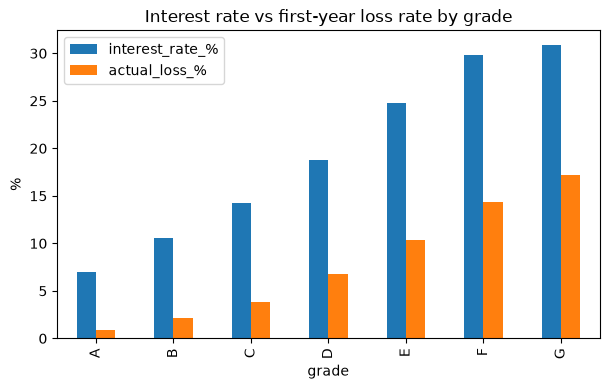

In [96]:
bt["int_x_funded"] = bt["int_rate"] * bt["funded_amnt"]
pricing = bt.groupby("grade")[["funded_amnt", "int_x_funded", "pred_loss", "actual_loss"]].sum()

pricing["interest_rate_%"] = pricing["int_x_funded"] / pricing["funded_amnt"]
pricing["expected_loss_%"] = pricing["pred_loss"] / pricing["funded_amnt"] * 100
pricing["actual_loss_%"] = pricing["actual_loss"] / pricing["funded_amnt"] * 100
pricing["risk_adj_yield_%"] = pricing["interest_rate_%"] - pricing["actual_loss_%"]
pricing["loss_share_of_yield_%"] = pricing["actual_loss_%"] / pricing["interest_rate_%"] * 100

pricing = pricing[["interest_rate_%", "expected_loss_%", "actual_loss_%",
                   "risk_adj_yield_%", "loss_share_of_yield_%"]].round(2)
print(pricing)

pricing[["interest_rate_%", "actual_loss_%"]].plot(kind="bar", figsize=(7, 4))
plt.title("Interest rate vs first-year loss rate by grade")
plt.ylabel("%")
plt.show()

## PSI: score stability
Population Stability Index compares the score distribution of new loans against the development sample, using train score deciles as bins.

PSI = Σ (actual % − expected %) × ln(actual % ÷ expected %)

🟢 < 0.10 stable · 🟡 0.10–0.25 monitor · 🔴 > 0.25 significant shift

In [97]:
def psi(expected, actual):
    expected, actual = expected.align(actual, fill_value=0)
    expected, actual = expected.clip(lower=1e-4), actual.clip(lower=1e-4)
    return ((actual - expected) * np.log(actual / expected)).sum()

def light(x):
    return "🟢" if x < 0.10 else ("🟡" if x < 0.25 else "🔴")

_, score_bins = pd.qcut(train_scored["score"], 10, retbins=True)
score_bins[0], score_bins[-1] = -np.inf, np.inf

dist = pd.DataFrame({
    "train_%": pd.cut(train_scored["score"], score_bins).value_counts(normalize=True, sort=False),
    "test_2017_%": pd.cut(test["score"], score_bins).value_counts(normalize=True, sort=False),
    "live_2018_%": pd.cut(live["score"], score_bins).value_counts(normalize=True, sort=False),
})

psi_2017 = psi(dist["train_%"], dist["test_2017_%"])
psi_2018 = psi(dist["train_%"], dist["live_2018_%"])

print((dist * 100).round(1))
print("\nPSI 2017:", round(psi_2017, 3), light(psi_2017))
print("PSI 2018:", round(psi_2018, 3), light(psi_2018))

                    train_%  test_2017_%  live_2018_%
score                                                
(-inf, 552.491]        10.0          9.3          7.7
(552.491, 563.045]     10.0          9.1          9.3
(563.045, 570.954]     10.0          9.9          9.1
(570.954, 577.473]     10.0         10.7          8.8
(577.473, 584.08]      10.0         10.3          8.7
(584.08, 591.279]      10.0         10.2          9.5
(591.279, 598.736]     10.0         10.5         10.4
(598.736, 607.587]     10.0         10.0          9.6
(607.587, 620.844]     10.0          9.7         12.6
(620.844, inf]         10.0         10.2         14.3

PSI 2017: 0.002 🟢
PSI 2018: 0.033 🟢


## CSI: which features drifted?
Characteristic Stability Index is the same calculation for each scorecard feature, using the scorecard's own bins. If score PSI moves, CSI shows which features are driving it.

In [98]:
edges, features = pd_art["edges"], pd_art["features"]

def get_bins(df, col):
    if col in edges:
        return pd.cut(df[col], bins=edges[col]).astype(str)
    s = df[col].clip(upper=3) if col in ["delinq_2yrs", "inq_last_6mths", "pub_rec"] else df[col]
    return s.astype(str)

csi = pd.DataFrame({"csi": {col: psi(get_bins(train, col).value_counts(normalize=True),
                                     get_bins(live, col).value_counts(normalize=True))
                            for col in features}}).sort_values("csi", ascending=False)
csi["status"] = csi["csi"].apply(light)
print(csi.round(3))

                        csi status
int_rate              0.106      🟡
grade                 0.102      🟡
verification_status   0.082      🟢
credit_history_years  0.027      🟢
inq_last_6mths        0.023      🟢
purpose               0.022      🟢
dti                   0.020      🟢
addr_state            0.006      🟢
home_ownership        0.002      🟢


## Save
Results tables for the Streamlit app.

In [99]:
by_stage.to_csv("../artifacts/ecl_by_stage.csv")
by_grade.to_csv("../artifacts/ecl_by_grade.csv")
scenarios.to_csv("../artifacts/ecl_scenarios.csv", index=False)
grid.to_csv("../artifacts/ecl_scenario_grid.csv", index=False)
backtest.to_csv("../artifacts/backtest_by_grade.csv")
pricing.to_csv("../artifacts/pricing_by_grade.csv")
dist.to_csv("../artifacts/psi_score_distribution.csv")
csi.to_csv("../artifacts/csi.csv")

test[["bad_12m", "pd_12m", "score"]].to_parquet("../artifacts/pd_test_scores.parquet", index=False)

pd.DataFrame({"metric": ["psi_2017", "psi_2018", "weighted_ecl", "base_ecl", "total_ead"],
              "value": [psi_2017, psi_2018, weighted_ecl, scenarios.loc[1, "ecl"], book["ead"].sum()]}
             ).to_csv("../artifacts/summary_metrics.csv", index=False)

## Findings
- **ECL:** $271.0mn on a $5,946.5mn book (4.56% coverage). Stage mix 94.6% / 3.8% / 1.6%, with coverage of 2.76% / 7.35% / 90.44%.
- **Lifetime uplift:** moving a loan to Stage 2 raises its provision 1.78x. Scenario-weighted ECL is $283.8mn (1.047x base).
- **SICR:** a 40-pt FICO drop flagged 12.4% of the book, mostly score noise (std of change ≈ 40 pts). The revised rule (60+ pt drop and now < 640) flags 3.8%. FICO triggers 12,813 Stage 2 loans and DPD 4,522.
- **Backtest (2017):** predicted 3.61% vs actual 3.92% loss rate (0.92). Accurate for C–D (0.97–1.01), understated for E–G (down to 0.76).
- **Pricing:** risk-adjusted yield rises from 6.05% (A) to 15.46% (F), then falls to 13.65% (G). First-year losses absorb 13% of grade A's interest income vs 56% of grade G's.
- **Stability:** score PSI 0.002 (2017) and 0.033 (2018), both green. The 2018 book shifted toward higher scores (top two deciles 26.9% vs 20%). CSI is amber for int_rate (0.106) and grade (0.102).

## Implications
- **Losses are driven by PD, not recovery** (LGD ~90%), so underwriting quality matters most.
- **Grades E–G are under-provisioned by ~13–24%.** Apply a PD overlay until the model is recalibrated.
- **Grade G is not paid for its risk.** Its rate is only ~1pp above F (30.9% vs 29.8%) because pricing nears a ~31% ceiling, while its losses are ~3pp higher. Tighten or exit G (a small share of the book).
- **SICR thresholds must be tested against score volatility.** A loose rule would have put 3x more loans into lifetime ECL on noise.
- **The model remains fit for use.** The population is stable; the int_rate/grade drift reflects LC's shift to better-quality borrowers in 2018 and should be monitored, not acted on.

## Limitations
- Origination PD only (no payment history), so Stage 2 ECL is likely understated.
- Scenario weights and multipliers are illustrative.
- LGD reflects LC's debt sales and is undiscounted.
- The 12-month default flag is inferred from the last payment date.
- One-year backtest in a benign credit environment; first-year loss understates lifetime loss.
- Yields exclude funding, servicing and operating costs.